# **Robustez del EDA de AFG2**

En este notebook complementaremos el análisis realizado en `03-jss-eda.ipynb`.

El objetivo es **robustecer el análisis aplicando una corrección por comparaciones múltiples (FDR) y evaluando la dependencia de las observaciones dentro de cada serie**. Haremos las estimaciones y pruebas para ver qué resultados obtenemos y si aportan al análisis.

En particular, responderemos dos preguntas:

1. ¿Los resultados exploratorios que aparecen como significativos se mantienen al corregir por comparaciones múltiples?
2. ¿El patrón observado para los pares candidatos según la distancia entre reuniones se mantiene cuando consideramos que los pares de una misma serie no son independientes?

Al final resumiremos qué resultados se mantienen y qué aportan al EDA principal.


# **Carga de datos**

Usaremos las mismas tablas construidas por `afg.eda` que utiliza el EDA principal.

La muestra contiene 14 series, cada una con cuatro reuniones. Para este análisis nos interesan especialmente los niveles de reunión, decisión, par y hablante-reunión.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from afg import eda

SEED = 0
ALPHA = 0.05
N_BOOT = 5_000

np.random.seed(SEED)

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

TABLES = eda.load_eda_tables()

SERIES = TABLES.series.copy()
MEETING = TABLES.meeting.copy()
SPEAKER = TABLES.speaker_meeting.copy()
DECISION = TABLES.decision.copy()
PAIR = TABLES.pair.copy()

print(f"Series: {len(SERIES)}")
print(f"Reuniones: {len(MEETING)}")
print(f"Hablantes-reunión: {len(SPEAKER)}")
print(f"Decisiones: {len(DECISION)}")
print(f"Pares: {len(PAIR)}")


Series: 14
Reuniones: 56
Hablantes-reunión: 224
Decisiones: 343
Pares: 3071


# **1. Corrección por comparaciones múltiples (FDR)**

En el EDA se realizan varias pruebas estadísticas. Si cada una se interpreta por separado con un nivel de significancia de 0,05, aumenta la probabilidad de obtener algún resultado significativo por azar.

Para revisar este punto aplicaremos el procedimiento de **Benjamini-Hochberg**, que controla la tasa de falsos descubrimientos (*False Discovery Rate*, FDR).

Para que el análisis sea reproducible, no copiaremos valores *p* desde el notebook principal. Volveremos a calcular programáticamente una familia de pruebas exploratorias ya presentes en el EDA:

- pruebas de independencia χ²;
- pruebas de Kruskal-Wallis.

No agregaremos pruebas nuevas solo para obtener resultados favorables.


## **1.1 Pruebas de independencia χ²**

Comenzaremos reconstruyendo cuatro comparaciones del EDA que pueden obtenerse directamente desde las tablas cargadas.


In [2]:
CONTINGENCY = {
    "Rol que respalda la decisión por sitio": (DECISION, "evidence_role", "site"),
    "Decisión con evidencia por sitio": (DECISION, "anchored", "site"),
    "Par candidato por distancia entre reuniones": (PAIR, "is_candidate", "meeting_distance"),
    "Par candidato por sitio": (PAIR, "is_candidate", "site"),
}

chi_rows = []

for nombre, (df, row, col) in CONTINGENCY.items():
    table = eda.contingency_table(df, row, col)
    result = eda.chi2_independence(table)

    chi_rows.append(
        {
            "analisis": nombre,
            "prueba": "chi2",
            "p_value": result.p_value,
        }
    )

chi_tests = pd.DataFrame(chi_rows)
display(chi_tests.round(6))


,analisis,prueba,p_value
0,Rol que respalda la decisión por sitio,chi2,0.344281
1,Decisión con evidencia por sitio,chi2,0.197079
2,Par candidato por distancia entre reuniones,chi2,0.019102
3,Par candidato por sitio,chi2,0.662806


## **1.2 Pruebas de Kruskal-Wallis**

Ahora reconstruiremos las comparaciones de Kruskal-Wallis del EDA para reunión, decisión, serie, par y hablante-reunión.


In [3]:
KRUSKAL_CASES = [
    ("reunión", MEETING, "duration_seconds", "site"),
    ("reunión", MEETING, "n_words", "site"),
    ("reunión", MEETING, "n_turns", "site"),
    ("reunión", MEETING, "n_decisions", "site"),
    ("reunión", MEETING, "n_decisions", "position"),
    ("reunión", MEETING, "n_words", "position"),
    ("decisión", DECISION, "n_tokens", "site"),
    ("decisión", DECISION, "n_tokens", "position"),
    ("serie", SERIES, "candidate_rate", "site"),
    ("par", PAIR, "overlap", "site"),
    ("par", PAIR, "overlap", "meeting_distance"),
    ("hablante-reunión", SPEAKER, "talk_share", "role"),
    ("hablante-reunión", SPEAKER, "n_decision_acts", "role"),
]

kruskal_rows = []

for nivel, df, variable, grupos in KRUSKAL_CASES:
    result = eda.kruskal_by_group(df, variable, grupos)

    kruskal_rows.append(
        {
            "analisis": f"{variable} por {grupos}",
            "nivel": nivel,
            "prueba": "Kruskal-Wallis",
            "p_value": result.p_value,
        }
    )

kruskal_tests = pd.DataFrame(kruskal_rows)
display(kruskal_tests.round(6))


,analisis,nivel,prueba,p_value
0,duration_seconds por site,reunión,Kruskal-Wallis,0.005081
1,n_words por site,reunión,Kruskal-Wallis,0.060569
2,n_turns por site,reunión,Kruskal-Wallis,0.077199
3,n_decisions por site,reunión,Kruskal-Wallis,0.078751
4,n_decisions por position,reunión,Kruskal-Wallis,0.003185
5,n_words por position,reunión,Kruskal-Wallis,0.000001
6,n_tokens por site,decisión,Kruskal-Wallis,0.000211
7,n_tokens por position,decisión,Kruskal-Wallis,0.621323
8,candidate_rate por site,serie,Kruskal-Wallis,0.893278
9,overlap por site,par,Kruskal-Wallis,0.000000


## **1.3 Aplicación de Benjamini-Hochberg**

Uniremos las 17 pruebas anteriores y ajustaremos sus valores *p*.

La columna `significativo_sin_FDR` indica qué resultados superan el umbral de 0,05 sin corrección. La columna `significativo_FDR` muestra cuáles se mantienen después del ajuste.


In [4]:
from afg.eda.stats import benjamini_hochberg

tests = pd.concat(
    [
        chi_tests.assign(nivel="varios"),
        kruskal_tests,
    ],
    ignore_index=True,
)

q_values, reject_fdr = benjamini_hochberg(tests["p_value"].to_numpy())

fdr = (
    tests.assign(
        q_BH=q_values,
        significativo_sin_FDR=tests["p_value"] < ALPHA,
        significativo_FDR=reject_fdr,
    )
    .sort_values("p_value")
    .reset_index(drop=True)
)

display(
    fdr[
        [
            "nivel",
            "analisis",
            "prueba",
            "p_value",
            "q_BH",
            "significativo_sin_FDR",
            "significativo_FDR",
        ]
    ].round(6)
)


,nivel,analisis,prueba,p_value,q_BH,significativo_sin_FDR,significativo_FDR
0,par,overlap por site,Kruskal-Wallis,0.000000,0.000000,True,True
1,hablante-reunión,talk_share por role,Kruskal-Wallis,0.000000,0.000000,True,True
2,hablante-reunión,n_decision_acts por role,Kruskal-Wallis,0.000000,0.000000,True,True
3,reunión,n_words por position,Kruskal-Wallis,0.000001,0.000005,True,True
4,par,overlap por meeting_distance,Kruskal-Wallis,0.000077,0.000261,True,True
5,decisión,n_tokens por site,Kruskal-Wallis,0.000211,0.000599,True,True
6,reunión,n_decisions por position,Kruskal-Wallis,0.003185,0.007736,True,True
7,reunión,duration_seconds por site,Kruskal-Wallis,0.005081,0.010796,True,True
8,varios,Par candidato por distancia entre reuniones,chi2,0.019102,0.036082,True,True
9,reunión,n_words por site,Kruskal-Wallis,0.060569,0.102967,False,False


In [5]:
n_tests = len(fdr)
n_nominal = int(fdr["significativo_sin_FDR"].sum())
n_fdr = int(fdr["significativo_FDR"].sum())
n_changed = int(
    (fdr["significativo_sin_FDR"] & ~fdr["significativo_FDR"]).sum()
)

print(f"Pruebas revisadas: {n_tests}")
print(f"Significativas antes de FDR: {n_nominal}")
print(f"Significativas después de FDR: {n_fdr}")
print(f"Resultados que dejan de ser significativos: {n_changed}")


Pruebas revisadas: 17
Significativas antes de FDR: 9
Significativas después de FDR: 9
Resultados que dejan de ser significativos: 0


### **Respuesta**

En esta familia de pruebas, **9 de 17 resultados son significativos antes de la corrección y los mismos 9 se mantienen después de aplicar Benjamini-Hochberg**. Ningún resultado que era significativo con el umbral nominal de 0,05 deja de serlo tras el ajuste.

Por lo tanto, la corrección por comparaciones múltiples **no cambia las señales exploratorias principales incluidas en esta revisión**.

Esto no significa que cualquier prueba posible del EDA quede automáticamente validada. La conclusión se limita a la familia definida arriba: las pruebas χ² y Kruskal-Wallis reconstruidas de forma reproducible.


# **2. Dependencia de las observaciones dentro de cada serie**

El segundo punto de robustez tiene que ver con la unidad de análisis.

El EDA contiene 3.071 pares, pero esos pares provienen de solo 14 series. Por lo tanto, no es razonable interpretar los 3.071 pares como observaciones completamente independientes.

Para revisar cuánto afecta esta dependencia utilizaremos un **bootstrap por serie**: en lugar de remuestrear pares individuales, remuestrearemos series completas y conservaremos todos los pares pertenecientes a cada serie seleccionada.

Usaremos un contraste que ya aparece en la pregunta P6 del EDA: la diferencia en la proporción de pares candidatos entre distancia 1 y distancia 3.


In [6]:
from afg.eda.stats import cluster_bootstrap

def candidate_rate_difference(df):
    near = df.loc[df["meeting_distance"] == 1, "is_candidate"].astype(float)
    far = df.loc[df["meeting_distance"] == 3, "is_candidate"].astype(float)

    return near.mean() - far.mean()


pair_boot = cluster_bootstrap(
    PAIR,
    cluster_col="series_id",
    statistic=candidate_rate_difference,
)

bootstrap_summary = pd.Series(
    {
        "Diferencia observada": pair_boot["estimate"],
        "Media bootstrap": pair_boot["boot_mean"],
        "IC 95% inferior": pair_boot["ci_low"],
        "IC 95% superior": pair_boot["ci_high"],
        "Series": pair_boot["n_clusters"],
        "Réplicas válidas": pair_boot["n_boot_valid"],
    }
).to_frame("valor")

display(bootstrap_summary.round(6))


,valor
Diferencia observada,0.025408
Media bootstrap,0.025503
IC 95% inferior,0.011779
IC 95% superior,0.039267
Series,14.000000
Réplicas válidas,5000.000000


La diferencia observada es aproximadamente **0,025**, es decir, cerca de **2,5 puntos porcentuales** más de pares candidatos a distancia 1 que a distancia 3.

Veamos ahora la distribución obtenida al remuestrear las series.


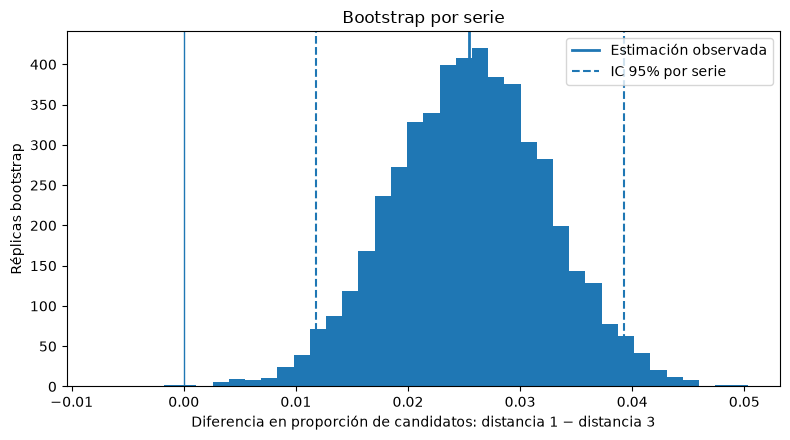

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(pair_boot["distribution"], bins=40)
ax.axvline(
    pair_boot["estimate"],
    linewidth=2,
    label="Estimación observada",
)
ax.axvline(
    pair_boot["ci_low"],
    linestyle="--",
    linewidth=1.5,
    label="IC 95% por serie",
)
ax.axvline(
    pair_boot["ci_high"],
    linestyle="--",
    linewidth=1.5,
)
ax.axvline(0, linewidth=1)

ax.set_xlabel(
    "Diferencia en proporción de candidatos: distancia 1 − distancia 3"
)
ax.set_ylabel("Réplicas bootstrap")
ax.set_title("Bootstrap por serie")
ax.legend()

fig.tight_layout()
plt.show()


In [8]:
ci_incluye_cero = bool(
    pair_boot["ci_low"] <= 0 <= pair_boot["ci_high"]
)

print(
    "IC 95%: "
    f"[{pair_boot['ci_low']:.6f}, {pair_boot['ci_high']:.6f}]"
)
print(f"¿El intervalo contiene cero? {'Sí' if ci_incluye_cero else 'No'}")


IC 95%: [0.011779, 0.039267]
¿El intervalo contiene cero? No


### **Respuesta**

El intervalo bootstrap al 95 % es aproximadamente **[0,0118; 0,0393]** y **no contiene cero**.

Esto indica que el patrón observado en P6 se mantiene cuando la incertidumbre se calcula remuestreando las 14 series completas. En otras palabras, la diferencia entre distancia 1 y distancia 3 **no parece explicarse solamente por tratar los 3.071 pares como si fueran observaciones independientes**.

El resultado también ayuda a precisar la interpretación: la evidencia de estabilidad proviene de las series, no del gran número nominal de pares.


# **3. ¿Qué aportan estos controles al EDA?**

Ya podemos responder las dos preguntas planteadas al inicio.

**Comparaciones múltiples.** En la familia de 17 pruebas χ² y Kruskal-Wallis revisadas, 9 resultados son significativos con el umbral nominal de 0,05 y los mismos 9 se mantienen después de la corrección FDR. Por lo tanto, en esta familia no observamos resultados significativos que desaparezcan al controlar comparaciones múltiples.

**Dependencia intra-serie.** Para el contraste de P6, la diferencia observada entre distancia 1 y distancia 3 es de aproximadamente 0,0254 y el intervalo bootstrap por serie es aproximadamente [0,0118; 0,0393]. Como el intervalo no contiene cero, el patrón se mantiene al respetar la agrupación de los pares dentro de las 14 series.

En conjunto, ambos controles **refuerzan las conclusiones exploratorias revisadas**, aunque no convierten el EDA en un análisis confirmatorio. El aporte es más acotado: dos posibles fuentes de fragilidad —multiplicidad y dependencia intra-serie— fueron revisadas y, para los resultados considerados aquí, no cambian la interpretación principal.


# **Resumen**

En este notebook robustecimos el EDA de AFG2 con dos análisis complementarios:

- Aplicamos Benjamini-Hochberg a una familia reproducible de 17 pruebas χ² y Kruskal-Wallis. Los 9 resultados significativos antes del ajuste continúan siendo significativos después del FDR.
- Evaluamos la dependencia de los pares dentro de cada serie mediante 5.000 réplicas bootstrap a nivel de serie. Para P6, el intervalo al 95 % de la diferencia entre distancia 1 y distancia 3 no contiene cero.
- Los dos controles apuntan en la misma dirección: **los resultados revisados no dependen de ignorar las comparaciones múltiples ni, en el contraste analizado, de tratar cada par como una observación independiente**.
- Las conclusiones siguen siendo exploratorias y deben interpretarse dentro de la muestra de 14 series AMI.

## **Reproducibilidad**

- Semilla: `0`.
- Nivel de significancia / FDR: `0,05`.
- Réplicas bootstrap: `5.000`.
- Unidad de remuestreo: `series_id`.
- Fuente de datos: `afg.eda.load_eda_tables()`.
- El notebook no modifica los datos ni el EDA principal.
